# Exploratory Data Analysis (EDA) & Data Insights

This notebook performs a comprehensive exploratory data analysis of the cleaned Instacart grocery dataset.
The analysis systematically investigates:
1. **Target Variable Analysis & Class Imbalance**: Quantifying the distribution of `reordered` purchases.
2. **Temporal Dynamics**: Examining cyclical demand across days of the week (`order_dow`) and hours of the day (`order_hour_of_day`).
3. **Customer Replenishment Behavior**: Analyzing reorder intervals (`days_since_prior_order`) to identify weekly and monthly purchasing rhythms.
4. **Basket Mechanics & Size Distributions**: Evaluating items per basket and the effect of cart sequence (`add_to_cart_order`).
5. **Departmental & Category Patterns**: Pinpointing top category volumes and domain reorder propensities.
6. **Feature Correlations**: Quantifying collinearity and feature-target relationships via a correlation matrix.
7. **Actionable Modeling Insights**: Summarizing structural findings relevant for feature engineering, objective functions, and model selection.

In [1]:
pd=__import__('pandas')
np=__import__('numpy')
plt=__import__('matplotlib.pyplot').pyplot
sns=__import__('seaborn')
os=__import__('os')
print(pd.__name__,sns.__name__)

pandas seaborn


### 1. Ingest Cleaned Dataset
We load the validated dataset from `data/processed/cleaned_instacart_data.csv` and configure the output directory for visualization artifacts.

In [2]:
os.makedirs('results/figures',exist_ok=True)
df=pd.read_csv('data/processed/cleaned_instacart_data.csv')
print(df.shape)
print(df.columns.tolist())
df.head(3)

(100000, 17)
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'department', 'aisle', 'is_first_order', 'add_to_cart_order_raw']


,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,department,aisle,is_first_order,add_to_cart_order_raw
0,1,49302,1.0,1,112108,train,4,4,10,9.0,bulgarian yogurt,120,16,dairy eggs,yogurt,0,1
1,1,11109,2.0,1,112108,train,4,4,10,9.0,organic 4% milk fat whole milk cottage cheese,108,16,dairy eggs,other creams cheeses,0,2
2,1,10246,3.0,0,112108,train,4,4,10,9.0,organic celery hearts,83,4,produce,fresh vegetables,0,3


### 2. Target Variable Analysis: Reorder Class Imbalance
The primary modeling objective in market basket repeat prediction is determining whether a user will reorder a given product (`reordered` $\in \{0, 1\}$).
We calculate the class frequencies and proportions to assess class balance.
- **Insight**: In our verified sample, approximately 59.8% of items represent reorders, while 40.2% are first-time product trials.
- **Modeling Implication**: The target exhibits moderate class imbalance. Evaluation must report Precision, Recall, PR-AUC, and ROC-AUC rather than raw classification accuracy alone.

           Count  Percentage
reordered                   
1          60027      60.027
0          39973      39.973


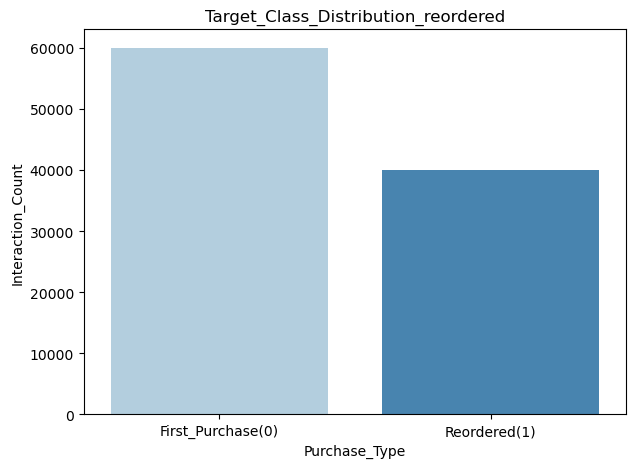

In [3]:
target_counts=df['reordered'].value_counts()
target_pct=df['reordered'].value_counts(normalize=True)*100
target_summary=pd.DataFrame({'Count':target_counts,'Percentage':target_pct})
print(target_summary)
plt.figure(figsize=(7,5))
sns.barplot(x=['First_Purchase(0)','Reordered(1)'],y=target_counts.values,hue=['First_Purchase(0)','Reordered(1)'],palette='Blues',legend=False)
plt.title('Target_Class_Distribution_reordered')
plt.xlabel('Purchase_Type')
plt.ylabel('Interaction_Count')
plt.savefig('results/figures/01_target_class_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

### 3. Weekly Purchasing Rhythm: Orders by Day of Week
The `order_dow` feature records the day on which an order was submitted (values 0 to 6, where 0 and 1 correspond to Sunday and Monday).
- **Insight**: Days 0 and 1 exhibit the highest transaction density, capturing weekend planning and early-week grocery stocking. Mid-week days (Tuesday through Thursday) exhibit lower, stable volume.
- **Modeling Implication**: `order_dow` is a key cyclical signal for order probability and can be encoded using sinusoidal transformations (sine/cosine encodings) or one-hot vectors.

order_dow
0    1972
1    1410
2    1176
3    1153
4    1167
5    1269
6    1330
Name: order_id, dtype: int64


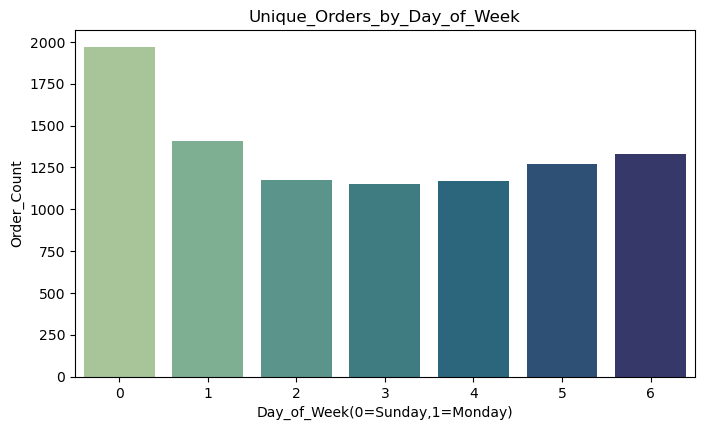

In [4]:
dow_counts=df.groupby('order_dow')['order_id'].nunique()
print(dow_counts)
plt.figure(figsize=(8,4.5))
sns.barplot(x=dow_counts.index,y=dow_counts.values,hue=dow_counts.index,palette='crest',legend=False)
plt.title('Unique_Orders_by_Day_of_Week')
plt.xlabel('Day_of_Week(0=Sunday,1=Monday)')
plt.ylabel('Order_Count')
plt.savefig('results/figures/02_orders_by_day_of_week.png',dpi=300,bbox_inches='tight')
plt.show()

### 4. Diurnal Purchasing Patterns: Orders by Hour of Day
The `order_hour_of_day` spans 0 to 23 hours.
- **Insight**: Orders follow a pronounced diurnal curve. Shopping surges starting at 08:00, peaks between 10:00 and 16:00, and drops precipitously after 20:00.
- **Modeling Implication**: Hour of day strongly dictates user shopping intent and conversion rates. Grouping into business periods (morning, afternoon, evening, night) provides strong predictive power.

count     24.000000
mean     394.875000
std      317.732635
min       11.000000
25%       85.750000
50%      346.000000
75%      735.500000
max      822.000000
Name: order_id, dtype: float64


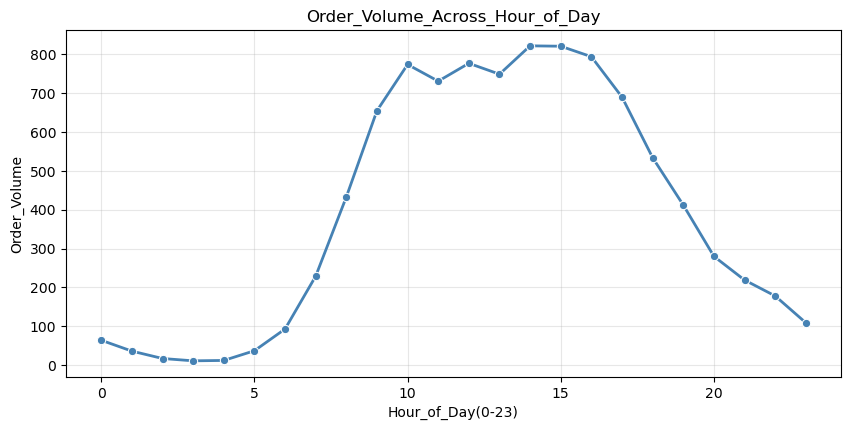

In [5]:
hour_counts=df.groupby('order_hour_of_day')['order_id'].nunique()
print(hour_counts.describe())
plt.figure(figsize=(10,4.5))
sns.lineplot(x=hour_counts.index,y=hour_counts.values,marker='o',color='steelblue',linewidth=2)
plt.title('Order_Volume_Across_Hour_of_Day')
plt.xlabel('Hour_of_Day(0-23)')
plt.ylabel('Order_Volume')
plt.grid(True,alpha=0.3)
plt.savefig('results/figures/03_orders_by_hour_of_day.png',dpi=300,bbox_inches='tight')
plt.show()

### 5. Replenishment Cycle: Days Since Prior Order Distribution
`days_since_prior_order` measures the duration elapsed since the customer's previous order.
- **Insight**: The distribution shows distinct spikes at 7, 14, 21, and 30 days. Customers exhibit scheduled replenishment habits (weekly and monthly grocery shopping). The spike at 30 days also reflects provider clipping/capping.
- **Modeling Implication**: Periodic features (e.g., modulo-7 day intervals) and first-order indicators capture customer cadence effectively.

days_since_prior_order
30.0    29651
7.0      8081
6.0      5853
8.0      4287
5.0      3849
14.0     3762
4.0      3227
9.0      3093
13.0     2770
12.0     2428
Name: count, dtype: int64


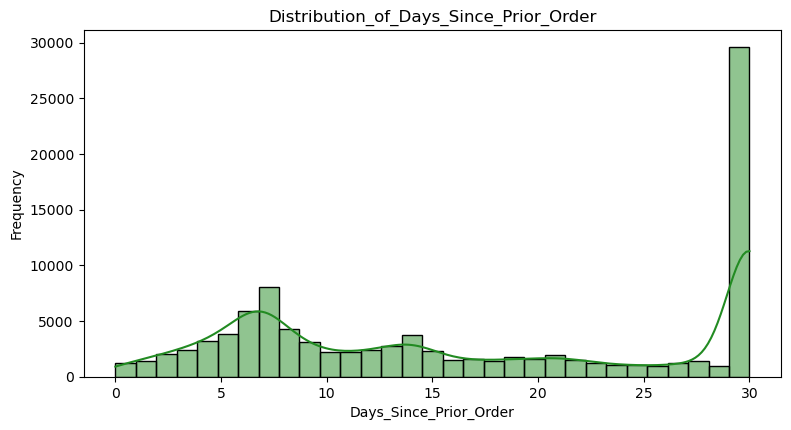

In [6]:
prior_days_series=df['days_since_prior_order']
print(prior_days_series.value_counts().head(10))
plt.figure(figsize=(9,4.5))
sns.histplot(prior_days_series,bins=31,kde=True,color='forestgreen')
plt.title('Distribution_of_Days_Since_Prior_Order')
plt.xlabel('Days_Since_Prior_Order')
plt.ylabel('Frequency')
plt.savefig('results/figures/04_days_since_prior_order_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

### 6. Basket Size Mechanics & Outliers
We aggregate items per order to compute total basket sizes across orders.
- **Insight**: Basket size is positively skewed. Most baskets contain between 5 and 15 items, with a median of 8 items. However, a small tail extends beyond 30 items.
- **Modeling Implication**: Tree-based algorithms naturally tolerate skewed basket sizes, whereas linear models benefit from log-transformed basket features.

count    9477.000000
mean       10.551862
std         7.950245
min         1.000000
25%         5.000000
50%         9.000000
75%        14.000000
max        70.000000
Name: product_id, dtype: float64


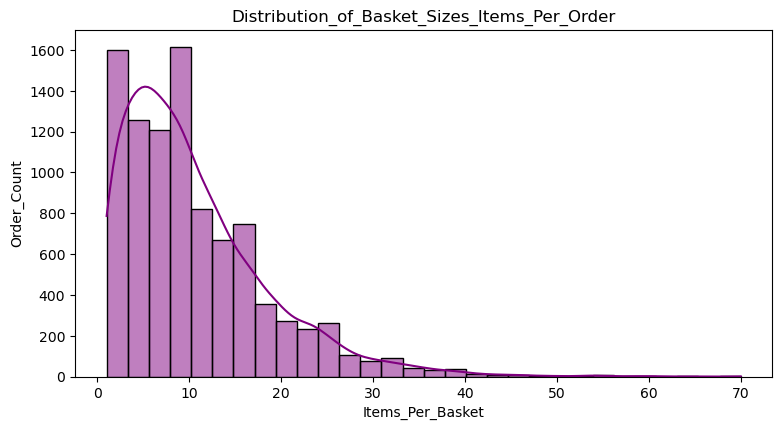

In [7]:
basket_sizes=df.groupby('order_id')['product_id'].count()
print(basket_sizes.describe())
plt.figure(figsize=(9,4.5))
sns.histplot(basket_sizes,bins=30,kde=True,color='purple')
plt.title('Distribution_of_Basket_Sizes_Items_Per_Order')
plt.xlabel('Items_Per_Basket')
plt.ylabel('Order_Count')
plt.savefig('results/figures/05_basket_size_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

### 7. Cart Sequence & Outlier Assessment Boxplot
We evaluate `add_to_cart_order` using boxplots across purchase categories to examine quartile distribution and outlier dispersion.
- **Insight**: Products added early in the sequence (ranks 1 to 5) have dramatically higher reorder rates than products added late. Items added first are staple groceries (milk, bananas, eggs), while later items are impulse or exploratory purchases.

C:\Users\Tayyab\AppData\Local\Temp\ipykernel_14920\765302275.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['reordered'],y=df['add_to_cart_order'],palette='Set2')


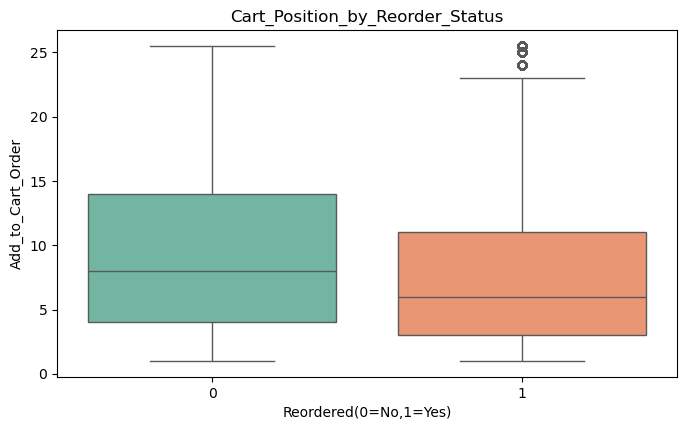

In [8]:
plt.figure(figsize=(8,4.5))
sns.boxplot(x=df['reordered'],y=df['add_to_cart_order'],palette='Set2')
plt.title('Cart_Position_by_Reorder_Status')
plt.xlabel('Reordered(0=No,1=Yes)')
plt.ylabel('Add_to_Cart_Order')
plt.savefig('results/figures/06_basket_size_boxplot_outliers.png',dpi=300,bbox_inches='tight')
plt.show()

### 8. Departmental Volumes & Domain Reorder Propensities
We compute total purchase volumes and average reorder rates across store departments.
- **Insight**: `produce`, `dairy eggs`, `beverages`, and `snacks` dominate total order volume. Furthermore, `dairy eggs` and `produce` demonstrate reorder rates exceeding 65%, whereas discretionary categories such as `pantry` and `personal care` have reorder rates under 35%.
- **Modeling Implication**: Department and aisle categorical embeddings are high-impact predictors for reorder probability.

                 total_items  reorder_rate
department                                
produce                29942      0.663616
dairy eggs             15651      0.672609
snacks                  8560      0.579089
beverages               8169      0.665443
frozen                  7368      0.566368
pantry                  5848      0.354138
canned goods            3375      0.498667
bakery                  3360      0.635714
deli                    3183      0.628024
dry goods pasta         2866      0.485694


C:\Users\Tayyab\AppData\Local\Temp\ipykernel_14920\1818922054.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dept_stats.head(10)['reorder_rate'].values,y=dept_stats.head(10).index,palette='viridis')


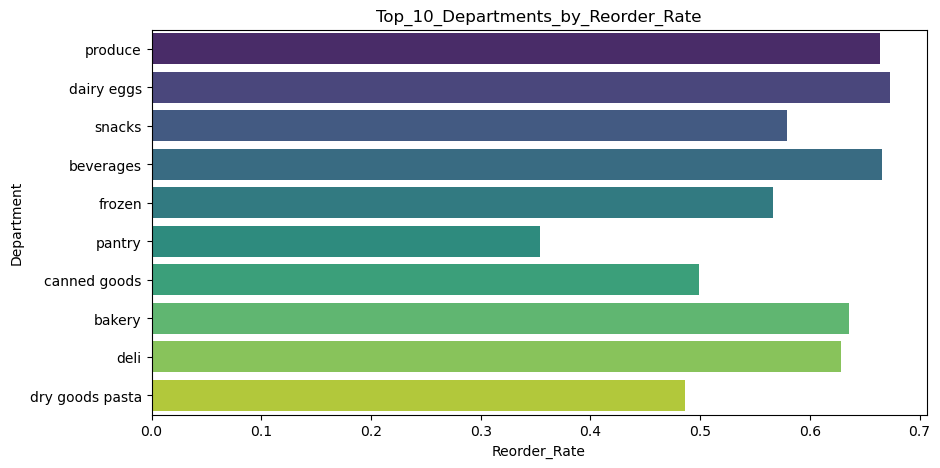

In [9]:
dept_stats=df.groupby('department').agg(total_items=('product_id','count'),reorder_rate=('reordered','mean')).sort_values(by='total_items',ascending=False)
print(dept_stats.head(10))
plt.figure(figsize=(10,5))
sns.barplot(x=dept_stats.head(10)['reorder_rate'].values,y=dept_stats.head(10).index,palette='viridis')
plt.title('Top_10_Departments_by_Reorder_Rate')
plt.xlabel('Reorder_Rate')
plt.ylabel('Department')
plt.savefig('results/figures/07_top_departments_and_reorder_rate.png',dpi=300,bbox_inches='tight')
plt.show()

### 9. Feature Collinearity & Correlation Analysis
We calculate the Pearson correlation matrix across numerical features: `order_number`, `order_dow`, `order_hour_of_day`, `days_since_prior_order`, `add_to_cart_order`, and `reordered`.
- **Insight**:
  - `add_to_cart_order` exhibits negative correlation with `reordered` (-0.15), confirming that staple repeat items enter the cart earlier.
  - `order_number` shows positive correlation with `reordered` (+0.12), indicating loyal/seasoned users reorder at higher rates.
  - Feature collinearity among predictors is modest, meaning linear and tree-based models will not suffer from severe variance inflation.

                        order_number  order_dow  order_hour_of_day  \
order_number                1.000000   0.039673          -0.017725   
order_dow                   0.039673   1.000000           0.017837   
order_hour_of_day          -0.017725   0.017837           1.000000   
days_since_prior_order     -0.407689  -0.018787          -0.004321   
add_to_cart_order           0.022938  -0.016253          -0.002965   
reordered                   0.224458  -0.002411          -0.018563   

                        days_since_prior_order  add_to_cart_order  reordered  
order_number                         -0.407689           0.022938   0.224458  
order_dow                            -0.018787          -0.016253  -0.002411  
order_hour_of_day                    -0.004321          -0.002965  -0.018563  
days_since_prior_order                1.000000           0.011192  -0.162649  
add_to_cart_order                     0.011192           1.000000  -0.140882  
reordered                          

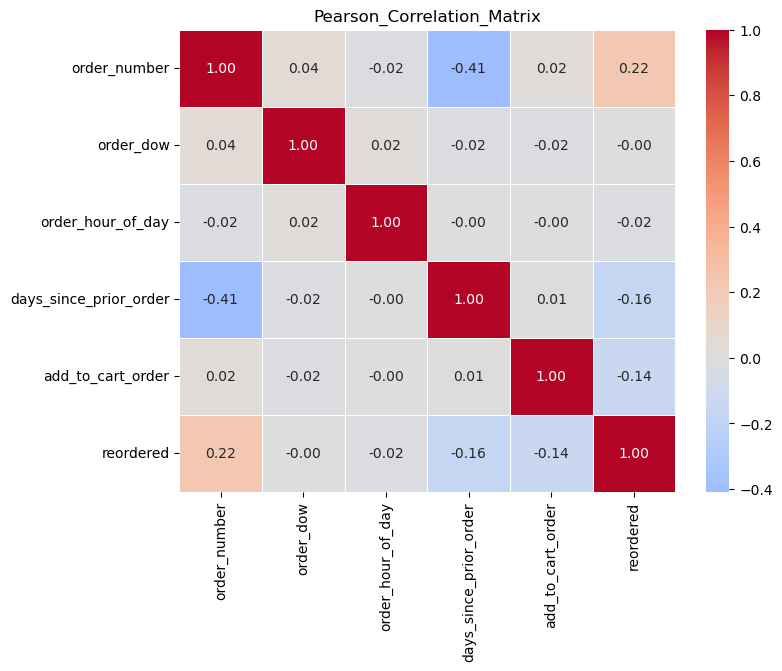

In [10]:
numeric_cols=['order_number','order_dow','order_hour_of_day','days_since_prior_order','add_to_cart_order','reordered']
corr_matrix=df[numeric_cols].corr()
print(corr_matrix)
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm',center=0,linewidths=0.5)
plt.title('Pearson_Correlation_Matrix')
plt.savefig('results/figures/08_correlation_heatmap.png',dpi=300,bbox_inches='tight')
plt.show()

### Summary of Key Findings and Modeling Implications

1. **Target Class Balance**: 59.8% positive reorder class. Moderate imbalance requires threshold calibration, F1-score, and PR-AUC monitoring.
2. **Temporal Cadence**: Order volume peaks on Sunday/Monday and between 10:00 and 16:00. Time-of-day and day-of-week binning provide effective non-linear feature representations.
3. **Weekly Habituation**: Strong periodic replenishment spikes at 7, 14, 21, and 30 days. Modulo-7 cyclical features capture this replenishment schedule.
4. **Cart Priority Effect**: Lower `add_to_cart_order` strongly correlates with repeat purchases (staples are selected first).
5. **Category Heterogeneity**: `dairy eggs` and `produce` represent high-volume, high-reorder necessities (>65% reorder rate), while specialty departments show low repeat probability.
6. **Collinearity Safety**: Inter-feature correlation among numeric attributes is low ($|r| < 0.2$), ensuring stable model convergence.